# EDS 220 HW4 Task 2: Visualizing fire scars through false color
#### Author: Sophia Soriano
#### GitHub Repository: https://github.com/ssoriano22/eds220-hwk4

## About

### Purpose:

This jupyter notebook documents the visualization of burn scars from the 2025 Eaton and Palisades fires in the Los Angeles (LA), California (CA) area using true color and false color (SWIR) imagery.

### Highlights:

1) Data exploration of CALFIRE Fire Perimeter geoDataFrame using geoPandas.
2) Data exploration and cleaning of Landsat 8 NetCDF data using xarray and rioxarray.
3) True color (RGB) image generation using Landsat 8 data.
4) False color (SWIR, NIR, red) image and map generation using Landsat 8 data, with CALFIRE fire perimeter data overlay to confirm burn areas.

### About the data:

**CALFIRE Data:** This dataset maintained by the California Department of Forestry and Fire Protection's Fire and Resource Assessment Program (FRAP) contains the polygon geometries corresponding to the recorded fire perimeters of the 2025 Eaton and Palisades fires in LA. There are expected to be only two rows in this dataset - one for each fire - with 18 columns containing the fire year, fire name, geometries, and other information on relevant parties reporting and handling the fire, along with fire causes and acerage. The authors of this dataset note that they have attempted to be as accurate as possible, but it is highly likely for missing data to exist given the nature of collecting fire data. See the CALFIRE data citation below.

**Landsat Data:** This NetCDF dataset - accessible through EarthExplorer - is provided by the U.S. Geological Survey (USGS) and contains Landsat 8 Operational Land Imager/Thermal Infrared Sensor (OLI/TIRS) Collection 2 Level-2 Science Products (L2SP) data - surface reflectance and surface temperature, both at a 30 meter spatial resolution. Additional data exploration is performed below defining dimensions (x,y), coordinates (x, y, time), and variables (bands). See the Landsat data citation below.

### References:

**CALFIRE Eaton and Palisades 2025 Shapefile Citation:** California Department of Forestry and Fire Protection. (2026). California fire perimeters (1950+) (Version firep25_1) [Data set]. California State Geoportal. https://gis.data.ca.gov/maps/c3c10388e3b24cec8a954ba10458039d/about

**Landsat Data Citation:** Earth Resources Observation and Science (EROS) Center. (2020). Landsat 8-9 Operational Land Imager / Thermal Infrared Sensor Level-2, Collection 2 [dataset]. U.S. Geological Survey. https://doi.org/10.5066/P9OGBGM6

## Section 1: Setup

In [ ]:
# Load packages
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import rioxarray as rioxr

## Section 2: CALFIRE Fire Perimeter Data Exploration

First, the CALFIRE fire perimeter data is loaded for the 2025 Eaton and Palisades fires:

In [2]:
# Load fire perimeter data - Eaton and Palisades shapefile
fp = os.path.join('data','California_Historic_Fire_Perimeters_7724575715026190580','California_Fire_Perimeters_(1950+).shp')
fire_perimeter = gpd.read_file(fp)

# Filter to 2025 only
fire_perimeter = fire_perimeter[fire_perimeter['YEAR_'] == 2025]

# Confirm load (should be 2 rows)
fire_perimeter

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,CAUSE,C_METHOD,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NA,IRWINID,FIRE_NUM,COMPLEX_ID,DECADES,geometry
0,2025,CA,CDF,LDF,PALISADES,00000738,2025-01-07,2025-01-31,14,7,1,23448.9,None,None,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},None,None,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13..."
1,2025,CA,CDF,LAC,EATON,00009087,2025-01-08,2025-01-31,14,7,1,14056.3,None,None,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},None,None,2020-2025,"MULTIPOLYGON (((-13146936.686 4051222.067, -13..."


As expected, only two rows are present in this CALFIRE dataset. The columns, geometries, CRS, and extent are explored below:

In [3]:
# Display fire_perimeter column info (type and non-null counts)
fire_perimeter.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2 entries, 0 to 1
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       2 non-null      int64   
 1   STATE       2 non-null      object  
 2   AGENCY      2 non-null      object  
 3   UNIT_ID     2 non-null      object  
 4   FIRE_NAME   2 non-null      object  
 5   INC_NUM     2 non-null      object  
 6   ALARM_DATE  2 non-null      object  
 7   CONT_DATE   2 non-null      object  
 8   CAUSE       2 non-null      int64   
 9   C_METHOD    2 non-null      int64   
 10  OBJECTIVE   2 non-null      int64   
 11  GIS_ACRES   2 non-null      float64 
 12  COMMENTS    0 non-null      object  
 13  COMPLEX_NA  0 non-null      object  
 14  IRWINID     2 non-null      object  
 15  FIRE_NUM    0 non-null      object  
 16  COMPLEX_ID  0 non-null      object  
 17  DECADES     2 non-null      object  
 18  geometry    2 non-null      geometry
dtypes: float6

In [4]:
# Check types of geometry in fire_perimeter
fire_perimeter.geom_type

0    MultiPolygon
1    MultiPolygon
dtype: object

In [5]:
# Check fire_perimeter crs
fire_perimeter.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
# Print specific info from crs
print('Ellipsoid: ', fire_perimeter.crs.ellipsoid)
print('Datum: ', fire_perimeter.crs.datum)
print('Is projected?: ', fire_perimeter.crs.is_projected)

Ellipsoid:  WGS 84
Datum:  World Geodetic System 1984 ensemble
Is projected?:  True


In [7]:
# Display extent of fire_perimeter (minx, miny, maxx, maxy)
print('CALFIRE GeoDataset Extent:')
print('minx:',fire_perimeter.total_bounds[0])
print('miny:',fire_perimeter.total_bounds[1])
print('maxx:',fire_perimeter.total_bounds[2])
print('maxy:',fire_perimeter.total_bounds[3])

CALFIRE GeoDataset Extent:
minx: -13212050.788800001
miny: 4032810.7585000023
maxx: -13137152.8556
maxy: 4060781.9439999983


This dataset containing fire perimeter polygon and multipolygon geometries for the 2025 Eaton and Palisades fires in California was downloaded from the CALFIRE geodata portal mentioned in the citation above. The dataset has 18 columns with 2 rows, one for the 2025 Eaton fire perimeter and one for the 2025 Palisades fire perimeter. The data used a projected 2D crs - EPSG:3857 - with an extent (meters) of minx: -13212050.7888, miny: 4032810.7585, maxx: -13137152.8556, maxy: 4060781.9440. The following columns have no data in either row: COMMENTS, COMPLEX_NA, FIRE_NUM, COMPLEX_ID.

## Section 3: Landsat 8 NetCDF Data Exploration

Here, the Landsat 8 NetCDF file is loaded using xr.open_dataset():

In [8]:
# Load landsat data as matrix (xr.open_dataaset())
fp2 = os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp2)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The landsat dataset has two dimensions - x with a size of 1418 and y with a size of 2742 - and three coordinates - y, x, and time. The landsat dataset variables correspond to the bands measured by the Landsat8 satellite - red, green, blue, nir08 (near infrared), swir22 (short wavelength infrared), and spatial_ref. The spatial_ref variable contains metadata describing this dataset. The projected 2D crs used is noted to be EPSG:32611 in the WKT above, and the units for projected 2D crs are expected to be meters.

## Section 4: Restoring geospatial information to Landsat data

Initially, the crs of the loaded Landsat data was checked:

In [9]:
# Display landsat crs using rio.crs
print("Landsat Dataset CRS:",landsat.rio.crs)

Landsat Dataset CRS: None


Trying to display the rio.crs attribute returns `None`, suggesting that the landsat dataset is not currently a geospatial object since it has no assigned CRS. Geospatial data is currently written in the WKT in the spatial_ref variable of the landsat dataset. This CRS WKT is displayed below:

In [20]:
# Display landsat crs wkt
print("Landsat CRS WKT:",landsat['spatial_ref'].attrs['crs_wkt'])


Landsat CRS WKT: PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


The CRS can be recovered from the final entry in this CRS WKT, and assigned to the Landsat dataset using rio.write_crs():

In [21]:
# Assign the final AUTHORITY[] EPSG to be the landsat crs using rio.write_crs()
landsat = landsat.rio.write_crs("EPSG:32611")

# Confirm crs update
print("Fixed Landsat CRS:",landsat.rio.crs)

Fixed Landsat CRS: EPSG:32611


The Landsat CRS was viewable in the crs_wkt attribute in the spatial_ref variable of the dataset, but it was not accessible using rioxarray. The rio.write_crs() function was used to manually add the final EPSG code in the spatial_ref crs_wkt (EPSG:32611) as the rio.crs attribute. This fix is confirmed in the print statment above.

## Section 5: True Color Image - Landsat

In an initial attempt to generate the true color Landsat image, the red, green, and blue bands (variables) from the Landsat dataset are selected, transformed into a DataArray, and plotted as an RGB image using imshow():

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


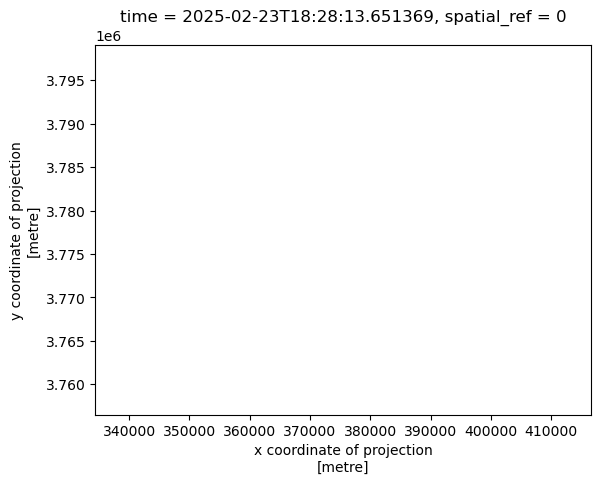

In [22]:
# Access r, g, b band variables, convert to dataarray, and plot
landsat[["red","green","blue"]].to_dataarray().plot.imshow()


This initial attempt produced an unhelpful white image with axes and a timestamp title, along with a message and warning statment (both of which will be discussed below). These issues will be corrected below, first by using `robust = TRUE` to adjust the RGB band scale:

/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


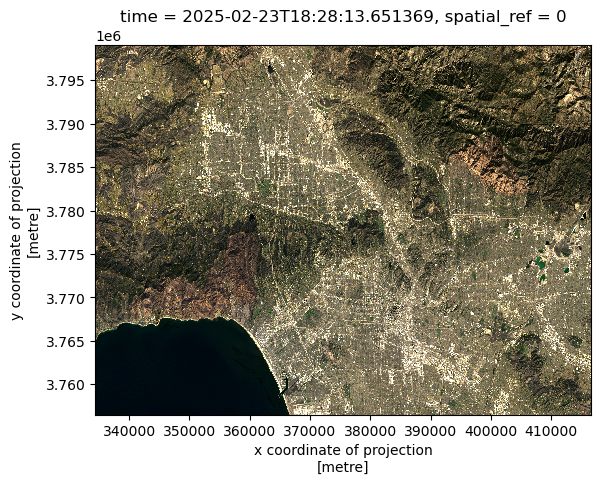

In [12]:
# Add the 'robust = True' argument:
#   Stretches the color scale to lessen the effect of extreme min and max pixel values
landsat[["red","green","blue"]].to_dataarray().plot.imshow(robust = True)

This gives us a visual image of the LA area, but the same warning is still present. To address this warning, the `numpy.isnan()` and `.fillna()` methods will be used to find and fill NaN pixel values with zeros:

In [13]:
# Determine how many nan values in each band of landsat
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

In [14]:
# Use fillna() to replace nans found above
landsat_fill = landsat.fillna(0)

# Confirm fillna() worked
np.isnan(landsat_fill).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 0
    blue         int64 8B 0
    nir08        int64 8B 0
    swir22       int64 8B 0

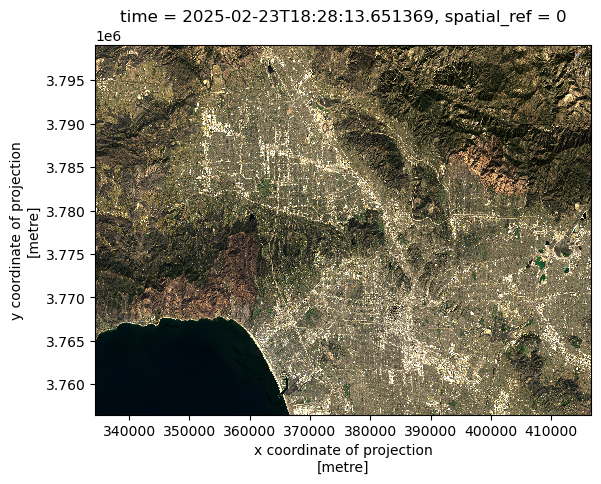

In [15]:
# Re-generate rgb image w/o nans
landsat_fill[["red","green","blue"]].to_dataarray().plot.imshow(robust = True)

A message and a warning resulted from initially attempting to plot the Landsat RGB array in step a, which only produced a white plot with projection axes and a timestamp title. The message stated that the imshow() method clipped the input landsat array data into a valid RGB range, which suggests that some band/variable data was not within the RGB range expected (0-255). Similarly, the warning mentioned that an "invalid value" was encounted while trying to change data types to perform int8 math. To address these issues, the 'robust = true' parameter was added to the imshow() method in order to stretch the data's RGB color values across the possible RGB range. Also, NaN values were discovered in the green (1) and blue (109) bands being plotted. These NaN values were filled with zeros, and the resulting `landsat_fill` dataset RGB bands were again transformed into an array and plotted in step e. This new image clearly displays an area in Los Angeles (LA) in true color, with two browner areas that likely correspond to the Eaton and Palisades fires.

## Section 6: False Color Image - Landsat

To create a false color version of the true color Landsat image above, the Landsat SWIR, NIR, and red bands are assigned to the red, green, and blue channels, respectively:

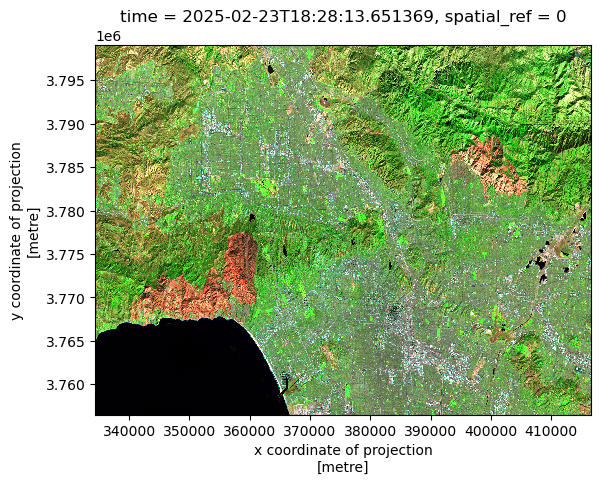

In [16]:
# Generate false color image using "swir22","nir08","red" bands/variables
landsat_fill[["swir22","nir08","red"]].to_dataarray().plot.imshow(robust = True)

The false color image above was generated using the following bands from the `landsat_fill` dataset: "swir22", "nir08", "red". Since there were no Nan values found in any of these bands, no zeros were imputed. This band combination is often used in remote sensing to visualize burn scars appearing in landscapes. Two orange areas are clear in this false color image, corresponding to the brown areas described above in the true color image of the same LA area.

## Section 7: False Color Map - Landsat and CALFIRE

The CRS of the CALFIRE dataset first needs to be reprojected to the Landsat CRS EPSG:32611 (a Western US Region CRS):

In [17]:
# Check if CRS currently match (likely not yet)
print("CALFIRE CRS:", fire_perimeter.crs)
print("Landsat CRS:", landsat_fill.rio.crs)

CALFIRE CRS: EPSG:3857
Landsat CRS: EPSG:32611


In [18]:
# Reproject fire_perimeter CRS to match Landsat EPSG:32611
#   Manually written to avoid getting entire wkt
fire_perimeter = fire_perimeter.to_crs("EPSG:32611")

# Check if CRS currently match (now they should)
print("CALFIRE CRS:", fire_perimeter.crs)
print("Landsat CRS:", landsat_fill.rio.crs)

assert fire_perimeter.crs == landsat_fill.rio.crs

CALFIRE CRS: EPSG:32611
Landsat CRS: EPSG:32611


Finally, a map is generated using the Landsat false color image as a base layer, with the CALFIRE 2025 Eaton and Palisades fire perimeters layered on top:

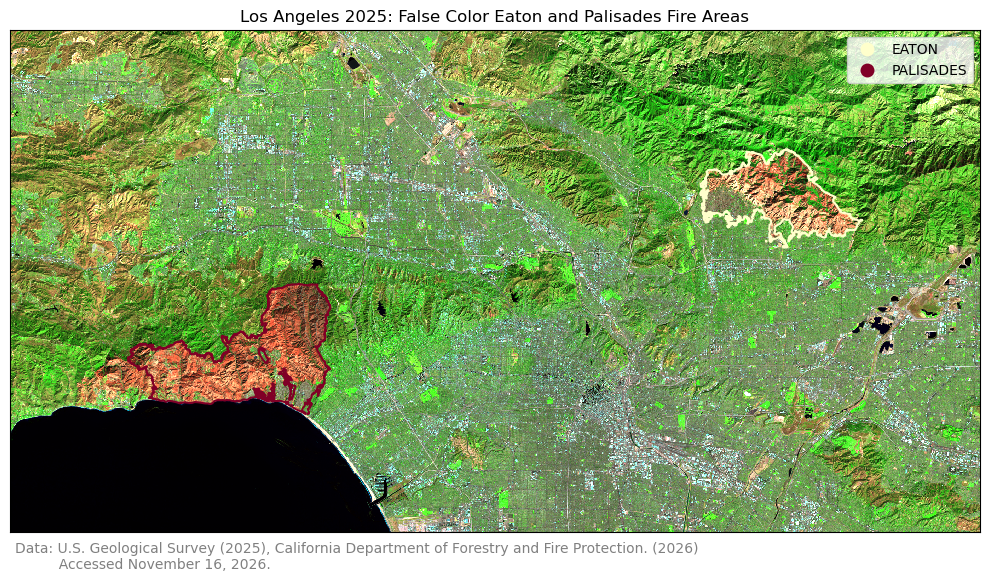

In [23]:
## DATA VISUALIZATION

# Initialize empty figure
fig, ax = plt.subplots(figsize = (10,8))

# Add landsat raster data to ax
landsat_fill[["swir22","nir08","red"]].to_dataarray().plot.imshow(
      ax = ax,
      # Stretch rgb
      robust = True,
      # Remove axes labels
      add_labels = False
)

# Add fire_perimeter vector data to ax
fire_perimeter.plot(ax = ax,
                  # Only keep borders
                  facecolor = "none",
                  # Color border by fire
                  column = "FIRE_NAME",
                  # Sepcify colors
                  cmap="YlOrRd",
                  # Set line width
                  linewidth=1.5,
                  # Display legend
                  legend = True,
                  # Specify legend location
                  legend_kwds={"loc": "upper right"}
)

# Set title
ax.set_title("Los Angeles 2025: False Color Eaton and Palisades Fire Areas")

# Remove xticks and yticks
ax.set_xticks([])
ax.set_yticks([])

# Add data caption
plt.figtext(0.02, 0.14,"Data: U.S. Geological Survey (2025), California Department of Forestry and Fire Protection. (2026) \n          Accessed November 16, 2026.", color = "grey")

# Display figure
plt.tight_layout()
plt.show()

Figure 1: The false color image above was generated using the following bands from the Landsat dataset: "swir22", "nir08", "red" (U.S. Geological Survey 2025). This band combination is often used in remote sensing to visualize burn scars appearing in landscapes, as the SWIR band - in the red channel - detects moisture and heat, the NIR band - in the green channel - detects vegetation - and the red band - in the blue channel - shows land types that reflect red light (i.e. ocean is very dark because it absorbs red light). Two orange areas denoting burn scars are clear in this false color image. Each area corresponds to a recorded fire perimeter, shown in either light yellow for the Eaton fire or in dark red for the Palisades fire (California Department of Forestry and Fire Protection 2026).